# Predicting Building Occupancy Using Machine Learning

## Project Overview

This project investigates whether time-based features can predict the maximum recorded hourly headcount in monitored building spaces using the Monash Smart Infrastructure occupancy dataset.

Three approaches are compared:

1. Mean-prediction baseline
2. Linear Regression
3. Decision Tree Regression

Model performance is evaluated using chronological training, validation and testing periods, with Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

The analysis focuses on the first 100,000 occupancy records. Only hours containing sensor observations are included.

**Objective:** Develop and evaluate a reproducible machine learning workflow for predicting recorded hourly occupancy peaks, while identifying limitations relating to irregular sampling and prediction accuracy.

In [1]:

import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Project configuration
SAMPLE_SIZE = 100_000
RANDOM_STATE = 42
TIMEZONE = "Australia/Melbourne"


In [2]:

from pathlib import Path

def load_occupancy_data(zip_path, sample_size=100_000):
    """
    Load occupancy records from the nested MSI dataset ZIP.

    Parameters
    ----------
    zip_path : str or Path
        Path to the original MSI dataset ZIP.
    sample_size : int
        Maximum number of occupancy records to load.

    Returns
    -------
    pandas.DataFrame
        Occupancy records with timestamps converted to
        Melbourne local time.

    Raises
    ------
    FileNotFoundError
        If the dataset ZIP does not exist.
    ValueError
        If the occupancy archive or CSV cannot be found.
    """
    zip_path = Path(zip_path)

    if not zip_path.is_file():
        raise FileNotFoundError(
            f"Dataset not found: {zip_path}"
        )

    if sample_size <= 0:
        raise ValueError("sample_size must be positive")

    with zipfile.ZipFile(zip_path) as outer_zip:
        occupancy_files = [
            name for name in outer_zip.namelist()
            if "occupancysensor" in name.lower()
            and name.lower().endswith(".zip")
        ]

        if not occupancy_files:
            raise ValueError("Occupancy archive not found")

        occupancy_bytes = outer_zip.read(
            occupancy_files[0]
        )

    with zipfile.ZipFile(
        io.BytesIO(occupancy_bytes)
    ) as inner_zip:

        csv_files = [
            name for name in inner_zip.namelist()
            if name.lower().endswith(".csv")
        ]

        if not csv_files:
            raise ValueError("Occupancy CSV not found")

        with inner_zip.open(csv_files[0]) as csv:
            data = pd.read_csv(
                csv,
                nrows=sample_size
            )

    required_columns = [
        "floorspaceid",
        "headcount",
        "collecteddate"
    ]

    missing = [
        col for col in required_columns
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    data["collecteddate"] = pd.to_datetime(
        data["collecteddate"],
        utc=True
    )

    data["local_time"] = (
        data["collecteddate"]
        .dt.tz_convert(TIMEZONE)
    )

    return data


In [3]:

# Locate the original MSI dataset archive
dataset_files = [
    path
    for folder in [Path("/content"), Path("/")]
    if folder.is_dir()
    for path in folder.glob("MMA3001 Dataset*.zip")
    if zipfile.is_zipfile(path)
]

if not dataset_files:
    raise FileNotFoundError(
        "Upload the original MMA3001 dataset ZIP."
    )

# Load the reproducible 100,000-record sample
occupancy_df = load_occupancy_data(
    dataset_files[0],
    sample_size=SAMPLE_SIZE
)

display(occupancy_df.head())
print(f"Successfully loaded {len(occupancy_df):,} records.")


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus,local_time
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-23 13:36:52+00:00,2023-11-24 00:36:52+11,NotOccupied,2023-11-24 00:36:52+11:00
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-23 13:37:32+00:00,2023-11-24 00:37:32+11,CurrentlyOccupied,2023-11-24 00:37:32+11:00
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-23 13:37:32+00:00,2023-11-24 00:37:32+11,NotOccupied,2023-11-24 00:37:32+11:00
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-23 13:37:52+00:00,2023-11-24 00:37:52+11,RecentlyOccupied,2023-11-24 00:37:52+11:00
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-23 13:37:52+00:00,2023-11-24 00:37:52+11,CurrentlyOccupied,2023-11-24 00:37:52+11:00


Successfully loaded 100,000 records.


In [4]:

from occupancy_utils import prepare_hourly_data

In [5]:

# Prepare the hourly prediction dataset
hourly_df = prepare_hourly_data(occupancy_df)

# Summarise the prepared dataset
print(f"Hourly records: {len(hourly_df):,}")
print(
    "Monitored spaces:",
    hourly_df["floorspaceid"].nunique()
)

display(hourly_df.head())


Hourly records: 1,969
Monitored spaces: 2


,floorspaceid,local_time,max_headcount,reading_count,hour,day_of_week
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2023-11-24 00:00:00+11:00,1,6,0,4
1,941f0352-bb69-47d0-a9c5-ac29eb4f7319,2023-11-24 00:00:00+11:00,1,6,0,4
2,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2023-11-24 03:00:00+11:00,1,3,3,4
3,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2023-11-24 05:00:00+11:00,2,7,5,4
4,941f0352-bb69-47d0-a9c5-ac29eb4f7319,2023-11-24 05:00:00+11:00,1,3,5,4


In [6]:

from occupancy_utils import split_hourly_data


In [7]:

# Create chronological data partitions
development_train, validation_df, train_df, test_df = (
    split_hourly_data(hourly_df)
)

# Define model inputs and target
features = ["hour", "day_of_week", "floorspaceid"]
target = "max_headcount"

X_dev = development_train[features]
y_dev = development_train[target]

X_val = validation_df[features]
y_val = validation_df[target]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

# Display partition sizes
partition_summary = pd.DataFrame({
    "Partition": [
        "Development training",
        "Validation",
        "Full training",
        "Final testing"
    ],
    "Records": [
        len(development_train),
        len(validation_df),
        len(train_df),
        len(test_df)
    ]
})

display(partition_summary)


,Partition,Records
0,Development training,1250
1,Validation,317
2,Full training,1567
3,Final testing,402


In [8]:

def create_models():
    """
    Create the regression models used in this project.

    Returns
    -------
    dict
        Named scikit-learn estimators and pipelines.
        Categorical preprocessing is fitted using
        training data only.
    """
    categorical_features = [
        "hour", "day_of_week", "floorspaceid"
    ]

    def make_preprocessor():
        return ColumnTransformer([
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ])

    return {
        "Baseline": DummyRegressor(strategy="mean"),

        "Linear Regression": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", LinearRegression())
        ]),

        "Tuned Decision Tree": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", DecisionTreeRegressor(
                max_depth=12,
                min_samples_leaf=5,
                random_state=RANDOM_STATE
            ))
        ])
    }


In [9]:

# Train models on development data
models = create_models()

validation_results = []

for name, model in models.items():
    model.fit(X_dev, y_dev)
    predictions = model.predict(X_val)

    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        )
    })

validation_results_df = pd.DataFrame(validation_results)

display(validation_results_df.round(3))


,Model,MAE,RMSE
0,Baseline,1.420,1.765
1,Linear Regression,0.998,1.312
2,Tuned Decision Tree,1.026,1.354


In [10]:

def evaluate_models(models, X_train, y_train, X_test, y_test):
    """
    Train regression models and evaluate their predictions.

    Parameters
    ----------
    models : dict
        Dictionary containing named regression estimators.
    X_train, X_test : pandas.DataFrame
        Training and testing features.
    y_train, y_test : pandas.Series
        Actual training and testing headcounts.

    Returns
    -------
    tuple
        DataFrame of evaluation metrics and dictionary
        of test predictions for each model.
    """
    results = []
    predictions = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        predicted = model.predict(X_test)

        predictions[name] = predicted

        results.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predicted)
            ),
            "R2": r2_score(y_test, predicted)
        })

    return pd.DataFrame(results), predictions


# Create fresh models and evaluate on the held-out test period
final_models = create_models()

final_results_df, final_predictions = evaluate_models(
    final_models,
    X_train,
    y_train,
    X_test,
    y_test
)

display(final_results_df.round(3))


,Model,MAE,RMSE,R2
0,Baseline,1.592,2.186,-0.004
1,Linear Regression,1.160,1.692,0.399
2,Tuned Decision Tree,1.135,1.657,0.424


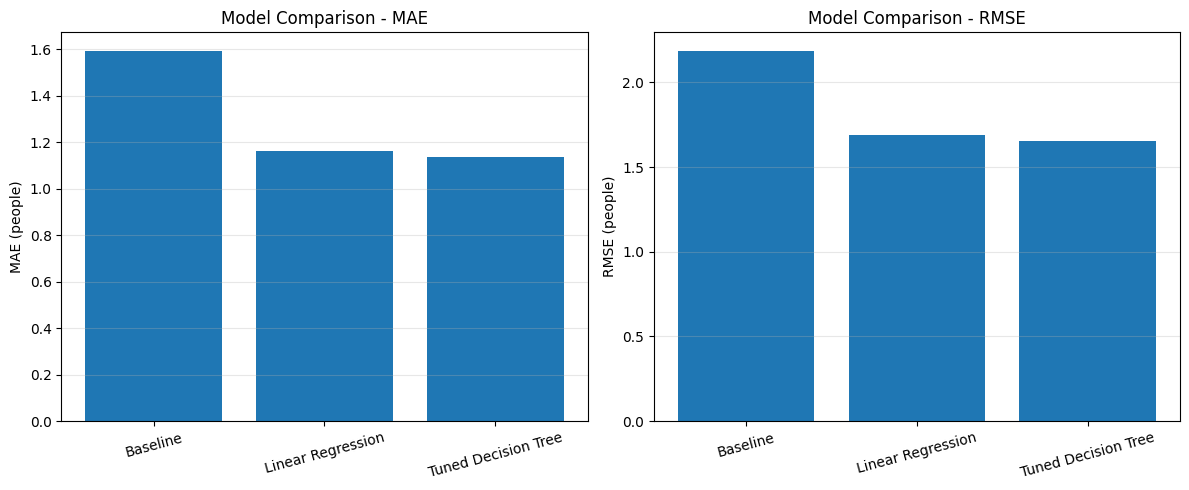

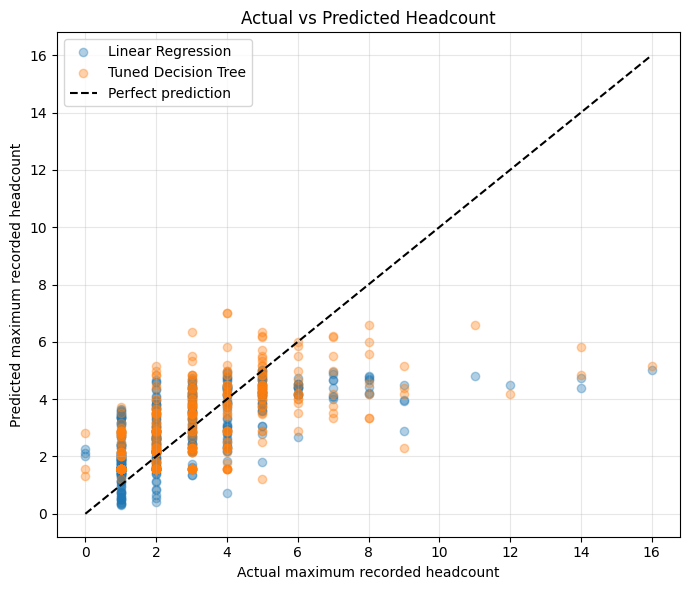

In [11]:

from pathlib import Path

# Create the folder for project figures
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

# Plot model performance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    ax.bar(
        final_results_df["Model"],
        final_results_df[metric]
    )
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(f"{metric} (people)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(figures_dir / "model_comparison.png", dpi=300)
plt.show()

# Plot actual versus predicted headcount
fig, ax = plt.subplots(figsize=(7, 6))

for name in ["Linear Regression", "Tuned Decision Tree"]:
    ax.scatter(
        y_test,
        final_predictions[name],
        alpha=0.35,
        label=name
    )

maximum = max(
    y_test.max(),
    *(np.max(final_predictions[name])
      for name in ["Linear Regression", "Tuned Decision Tree"])
)

ax.plot(
    [0, maximum],
    [0, maximum],
    "k--",
    label="Perfect prediction"
)

ax.set_xlabel("Actual maximum recorded headcount")
ax.set_ylabel("Predicted maximum recorded headcount")
ax.set_title("Actual vs Predicted Headcount")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(figures_dir / "actual_vs_predicted.png", dpi=300)
plt.show()
